<a href="https://colab.research.google.com/github/192565074simats-code/MLA0201/blob/main/Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

========== TRAINING DATASET ==========


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0



Total Samples: 442
Total Features: 10

Training Samples: 353
Testing Samples: 89

========== MODEL TRAINING COMPLETED ==========
Algorithm: Linear Regression

========== PREDICTION RESULTS ==========


,Actual Values,Predicted Values
0,219.0,139.55
1,70.0,179.52
2,202.0,134.04
3,230.0,291.42
4,111.0,123.79
5,84.0,92.17
6,242.0,258.23
7,272.0,181.34
8,94.0,90.22
9,96.0,108.63


Mean Squared Error: 2900.19
Mean Absolute Error: 42.79
R2 Score: 0.4526
R2 Accuracy: 45.26 %

========== FINAL REGRESSION EQUATION ==========
Intercept: 151.3456
age : 37.904
sex : -241.9644
bmi : 542.4288
bp : 347.7038
s1 : -931.4888
s2 : 518.0623
s3 : 163.42
s4 : 275.3179
s5 : 736.1989
s6 : 48.6707


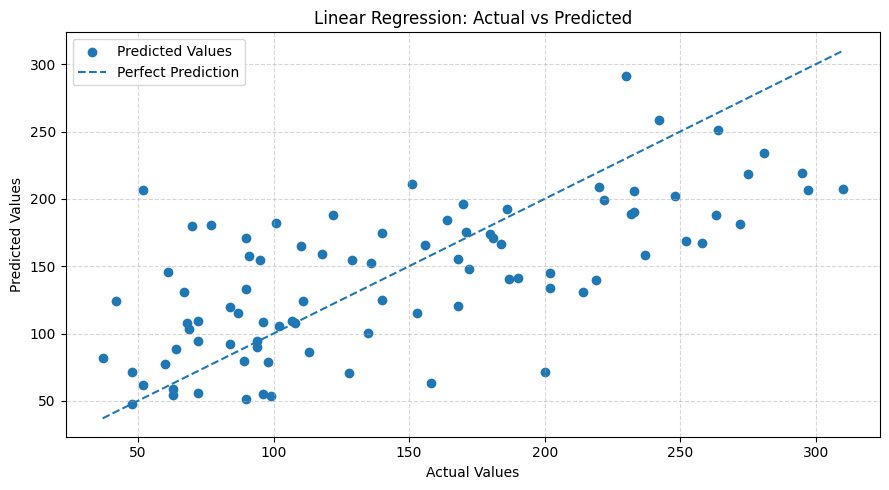

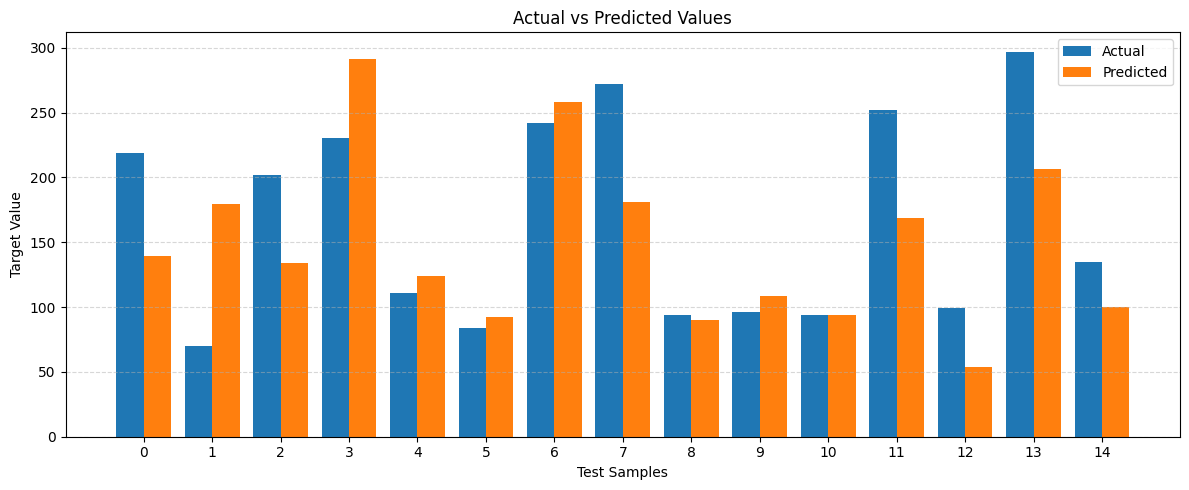

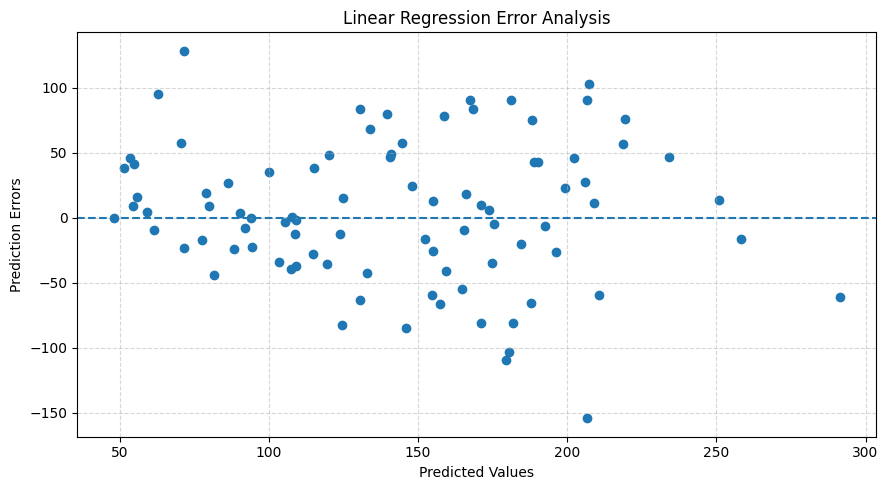

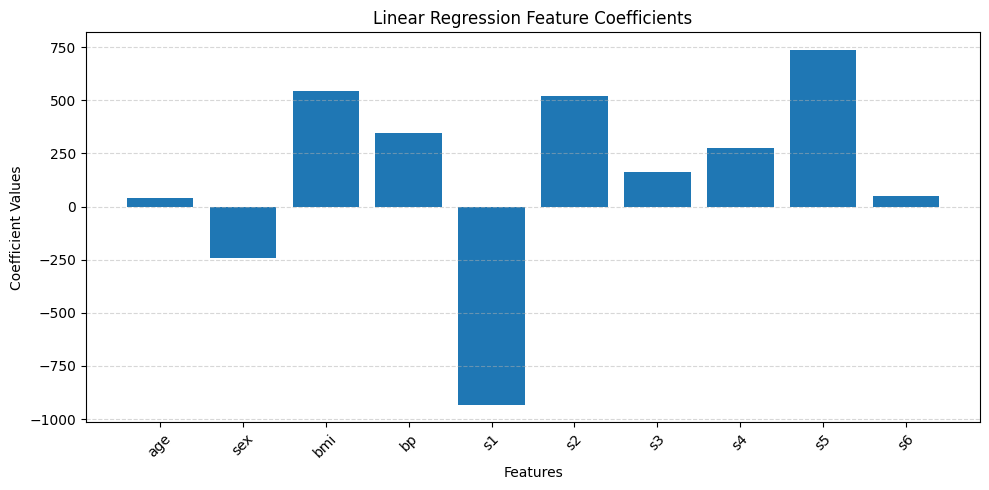


========== NEW SAMPLE PREDICTION ==========
Input Features: [ 0.04534098 -0.04464164 -0.00620595 -0.01599898  0.1250187   0.1251981
  0.019187    0.03430886  0.03243232 -0.0052198 ]
Predicted Target Value: 139.55

========== RESULT ==========
Linear Regression Implemented Successfully.
Mean Squared Error: 2900.19
R2 Score: 0.4526
Model Prediction Completed Successfully.


In [1]:
# EXPERIMENT 8: LINEAR REGRESSION USING PYTHON

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# STEP 1: LOAD TRAINING DATASET

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

df = pd.DataFrame(X, columns=diabetes.feature_names)
df['Target'] = y

print("========== TRAINING DATASET ==========")
display(df.head(10))

print("\nTotal Samples:", len(df))
print("Total Features:", X.shape[1])

# STEP 2: SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 3: CREATE LINEAR REGRESSION MODEL

model = LinearRegression()

# STEP 4: TRAIN THE MODEL

model.fit(X_train, y_train)

print("\n========== MODEL TRAINING COMPLETED ==========")
print("Algorithm: Linear Regression")

# STEP 5: PREDICT TEST DATA

y_pred = model.predict(X_test)

# STEP 6: EVALUATE MODEL

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n========== PREDICTION RESULTS ==========")

results = pd.DataFrame({
    'Actual Values': y_test,
    'Predicted Values': np.round(y_pred, 2)
})

display(results.head(15))

print("Mean Squared Error:", round(mse, 2))
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 4))
print("R2 Accuracy:", round(r2 * 100, 2), "%")

# STEP 7: DISPLAY FINAL REGRESSION EQUATION

print("\n========== FINAL REGRESSION EQUATION ==========")

print("Intercept:", round(model.intercept_, 4))

for feature, coefficient in zip(
    diabetes.feature_names,
    model.coef_
):
    print(feature, ":", round(coefficient, 4))

# STEP 8: ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(9, 5))

plt.scatter(
    y_test,
    y_pred,
    label='Predicted Values'
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    label='Perfect Prediction'
)

plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 9: BAR GRAPH

sample_count = min(15, len(y_test))
sample_index = np.arange(sample_count)

plt.figure(figsize=(12, 5))

plt.bar(
    sample_index - 0.2,
    y_test[:sample_count],
    width=0.4,
    label='Actual'
)

plt.bar(
    sample_index + 0.2,
    y_pred[:sample_count],
    width=0.4,
    label='Predicted'
)

plt.title("Actual vs Predicted Values")
plt.xlabel("Test Samples")
plt.ylabel("Target Value")
plt.xticks(sample_index)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 10: ERROR ANALYSIS GRAPH

errors = y_test - y_pred

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred,
    errors
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title("Linear Regression Error Analysis")
plt.xlabel("Predicted Values")
plt.ylabel("Prediction Errors")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 11: COEFFICIENT BAR GRAPH

plt.figure(figsize=(10, 5))

plt.bar(
    diabetes.feature_names,
    model.coef_
)

plt.title("Linear Regression Feature Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient Values")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# STEP 12: NEW SAMPLE PREDICTION

new_sample = X_test[:1]

new_prediction = model.predict(new_sample)

print("\n========== NEW SAMPLE PREDICTION ==========")

print("Input Features:", new_sample[0])

print("Predicted Target Value:", round(new_prediction[0], 2))

# STEP 13: FINAL RESULT

print("\n========== RESULT ==========")

print("Linear Regression Implemented Successfully.")

print("Mean Squared Error:", round(mse, 2))

print("R2 Score:", round(r2, 4))

print("Model Prediction Completed Successfully.")